# Customer Behaviour Analysis: RFM + K-Means Segmentation

**Goal:** split a shop's customers into groups based on how they buy, so the business can treat each group differently (reward the best, win back the lost).

**Data:** UCI *Online Retail* dataset: every sale from a UK online gift shop between **1 Dec 2010 and 9 Dec 2011** (about 540,000 rows). Download it from the UCI repository and save it as `data/Online Retail.xlsx`.

**Plan:** 1) load, 2) clean, 3) explore, 4) build RFM features, 5) log-transform and scale, 6) choose K, 7) cluster and name the groups, 8) business recommendations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True})

## 1. Load the data
Each row is one product on one invoice. The columns are: `InvoiceNo` (order number, starts with **C** if cancelled), `StockCode` (product code), `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID` and `Country`.

In [2]:
raw = pd.read_excel("data/Online Retail.xlsx")
raw["InvoiceNo"] = raw["InvoiceNo"].astype(str)
raw["StockCode"] = raw["StockCode"].astype(str)
print("Rows, columns:", raw.shape)
print()
print(raw.dtypes)
print()
print(raw.head())
print()
print("Missing values per column:")
print(raw.isna().sum())

Rows, columns: (541909, 8)

InvoiceNo                 str
StockCode                 str
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

  InvoiceNo StockCode                          Description  Quantity         InvoiceDate  UnitPrice  CustomerID         Country
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6 2010-12-01 08:26:00       2.55     17850.0  United Kingdom
1    536365     71053                  WHITE METAL LANTERN         6 2010-12-01 08:26:00       3.39     17850.0  United Kingdom
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8 2010-12-01 08:26:00       2.75     17850.0  United Kingdom
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6 2010-12-01 08:26:00       3.39     17850.0  United Kingdom
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6 2010-12-

## 2. Clean the data
Bad data gives bad groups, so we remove:
1. rows with **no CustomerID** (we can't tell whose purchase it is, and guessing an ID would invent a fake customer),
2. **exact duplicate** rows (they would double-count sales),
3. **cancellations**, and the original orders they reversed (a cancelled order is not a real purchase; I found this when one product showed 80,995 units that were cancelled 12 minutes later),
4. **non-product rows** like postage, manual adjustments and bank fees (they are not things customers chose to buy),
5. rows with **zero or negative quantity or price** (errors).

Then we create `TotalPrice = Quantity x UnitPrice`.

In [3]:
df = raw.copy()
log = [("Raw data", len(df))]

# 1. no CustomerID
df = df.dropna(subset=["CustomerID"])
log.append(("After dropping rows with no CustomerID", len(df)))

# 2. exact duplicates
df = df.drop_duplicates()
log.append(("After dropping exact duplicate rows", len(df)))

# 3. cancellations, plus the original orders they reversed
is_cancel = df["InvoiceNo"].str.startswith("C")
key = ["CustomerID", "StockCode", "UnitPrice"]
cancels = df[is_cancel].copy()
cancels["Quantity"] = cancels["Quantity"].abs()
n_cancel = cancels.groupby(key + ["Quantity"]).size().rename("n_cancel").reset_index()
buys = df[~is_cancel].copy()
buys["rank_latest"] = buys.groupby(key + ["Quantity"])["InvoiceDate"].rank(method="first", ascending=False) - 1
buys = buys.merge(n_cancel, on=key + ["Quantity"], how="left")
reversed_rows = buys["n_cancel"].notna() & (buys["rank_latest"] < buys["n_cancel"])
df = buys[~reversed_rows].drop(columns=["rank_latest", "n_cancel"]).sort_values("InvoiceDate")
log.append((f"After dropping {is_cancel.sum()} cancel rows + {reversed_rows.sum()} reversed orders", len(df)))

# 4. non-product codes
NON_PRODUCT = ["POST", "DOT", "M", "m", "D", "S", "B", "BANK CHARGES", "AMAZONFEE", "CRUK", "C2"]
n_nonprod = df["StockCode"].isin(NON_PRODUCT).sum()
df = df[~df["StockCode"].isin(NON_PRODUCT)]
log.append((f"After dropping {n_nonprod} non-product rows", len(df)))

# 5. zero / negative quantity or price
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
log.append(("After dropping quantity<=0 or price<=0", len(df)))

df["CustomerID"] = df["CustomerID"].astype(int)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

for step, n in log:
    print(f"{step:<62}{n:>9,}")
print()
print(f"Kept {len(df)/len(raw):.1%} of raw rows")
print("Customers:", df["CustomerID"].nunique(), "| Invoices:", df["InvoiceNo"].nunique(),
      "| Products:", df["StockCode"].nunique(), "| Countries:", df["Country"].nunique())
print("Date range:", df["InvoiceDate"].min().date(), "to", df["InvoiceDate"].max().date())
print(f"Total revenue: {df['TotalPrice'].sum():,.2f}")

Raw data                                                        541,909
After dropping rows with no CustomerID                          406,829
After dropping exact duplicate rows                             401,604
After dropping 8872 cancel rows + 3051 reversed orders          389,681
After dropping 1479 non-product rows                            388,202
After dropping quantity<=0 or price<=0                          388,168

Kept 71.6% of raw rows
Customers: 4322 | Invoices: 18242 | Products: 3645 | Countries: 37
Date range: 2010-12-01 to 2011-12-09
Total revenue: 8,345,010.36


## 3. Explore the data (EDA)
Look before you model. Four quick questions: when do sales happen, where, what sells, and how do customers differ?

InvoiceDate
2010-12     556
2011-01     467
2011-02     440
2011-03     574
2011-04     442
2011-05     652
2011-06     645
2011-07     585
2011-08     628
2011-09     928
2011-10     969
2011-11    1121
2011-12     341
Freq: M


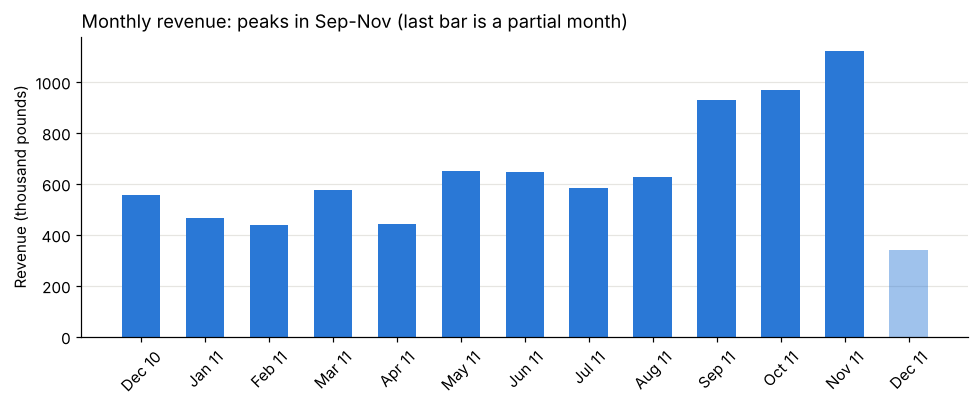

In [4]:
monthly = df.groupby(df["InvoiceDate"].dt.to_period("M"))["TotalPrice"].sum()
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.bar([m.strftime("%b %y") for m in monthly.index.to_timestamp()], monthly.values / 1000, color=BLUE, width=0.6)
bars[-1].set_alpha(0.45)   # December 2011 has only 9 days of data
ax.set_ylabel("Revenue (thousand pounds)")
ax.set_title("Monthly revenue: peaks in Sep-Nov (last bar is a partial month)", loc="left")
ax.grid(axis="x", visible=False)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
print((monthly / 1000).round(0).astype(int).to_string())

In [5]:
country = df.groupby("Country")["TotalPrice"].sum().sort_values(ascending=False)
print(f"UK share of revenue: {country['United Kingdom'] / country.sum():.1%}")
print("Top 6 countries (pounds):")
print(country.head(6).round(0).astype(int).to_string())

UK share of revenue: 82.4%
Top 6 countries (pounds):
Country
United Kingdom    6873684
Netherlands        283480
EIRE               247724
Germany            203624
France             182006
Australia          137063


In [6]:
products = df.groupby("Description")["TotalPrice"].sum().sort_values(ascending=False).head(10)
print("Top 10 products by revenue (pounds):")
print(products.round(0).astype(int).to_string())

Top 10 products by revenue (pounds):
Description
REGENCY CAKESTAND 3 TIER              137690
WHITE HANGING HEART T-LIGHT HOLDER     93918
JUMBO BAG RED RETROSPOT                83482
PARTY BUNTING                          67955
ASSORTED COLOUR BIRD ORNAMENT          56364
RABBIT NIGHT LIGHT                     51189
CHILLI LIGHTS                          45930
PAPER CHAIN KIT 50'S CHRISTMAS         41543
PICNIC BASKET WICKER 60 PIECES         39620
BLACK RECORD COVER FRAME               39001


Mean spend per customer:   1,931
Median spend per customer: 657   (mean is much higher: a few huge customers pull it up)
Top 20% of customers produce 73.8% of revenue
One-time buyers: 34.7% | repeat buyers: 65.3%


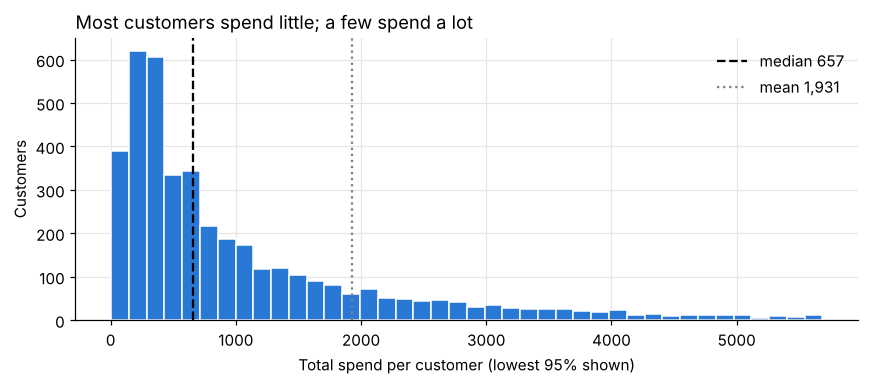

In [7]:
spend = df.groupby("CustomerID")["TotalPrice"].sum()
orders = df.groupby("CustomerID")["InvoiceNo"].nunique()
top20 = spend.sort_values(ascending=False).head(int(len(spend) * 0.2)).sum() / spend.sum()
print(f"Mean spend per customer:   {spend.mean():,.0f}")
print(f"Median spend per customer: {spend.median():,.0f}   (mean is much higher: a few huge customers pull it up)")
print(f"Top 20% of customers produce {top20:.1%} of revenue")
print(f"One-time buyers: {(orders == 1).mean():.1%} | repeat buyers: {(orders > 1).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(spend[spend <= spend.quantile(0.95)], bins=40, color=BLUE, edgecolor="white")
ax.axvline(spend.median(), color="black", linestyle="--", label=f"median {spend.median():,.0f}")
ax.axvline(spend.mean(), color="grey", linestyle=":", label=f"mean {spend.mean():,.0f}")
ax.set_xlabel("Total spend per customer (lowest 95% shown)"); ax.set_ylabel("Customers")
ax.set_title("Most customers spend little; a few spend a lot", loc="left"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. Build RFM features
For each customer we make a "card" with three numbers:
- **Recency (R):** days since their last purchase. **Lower is better.**
- **Frequency (F):** number of orders (unique invoices).
- **Monetary (M):** total money spent.

Recency needs a "today". We pretend today is the day after the last sale in the data (10 Dec 2011).

In [8]:
snapshot = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print("Snapshot ('today') date:", snapshot.date())

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda s: (snapshot - s.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
).reset_index()

print("Customers:", len(rfm))
print(rfm[["Recency", "Frequency", "Monetary"]].describe().round(1))
print()
print("Skewness (0 = symmetric, above 1 = very lopsided):")
print(rfm[["Recency", "Frequency", "Monetary"]].skew().round(2))

Snapshot ('today') date: 2011-12-10
Customers: 4322
       Recency  Frequency  Monetary
count   4322.0     4322.0    4322.0
mean      92.4        4.2    1930.8
std      100.3        7.6    8330.9
min        0.0        1.0       2.9
25%       17.0        1.0     301.8
50%       50.0        2.0     656.6
75%      143.0        5.0    1615.3
max      373.0      205.0  278778.0

Skewness (0 = symmetric, above 1 = very lopsided):
Recency       1.24
Frequency    11.96
Monetary     21.38
dtype: float64


## 5. Log-transform and scale
- The numbers are very **lopsided** (a few giant customers). A **log transform** (`log1p`, which is log(1+x) so zeros are safe) squeezes big values and keeps the order.
- K-Means works with **distances**, so features must be on the same scale. `StandardScaler` rescales each to mean 0 and standard deviation 1.
- Order matters: log first, then scale.

Skewness after log:
Recency     -0.47
Frequency    1.22
Monetary     0.37
dtype: float64

Scaled means (about 0): {'R_scaled': 0.0, 'F_scaled': 0.0, 'M_scaled': -0.0}
Scaled std devs (about 1): {'R_scaled': 1.0, 'F_scaled': 1.0, 'M_scaled': 1.0}


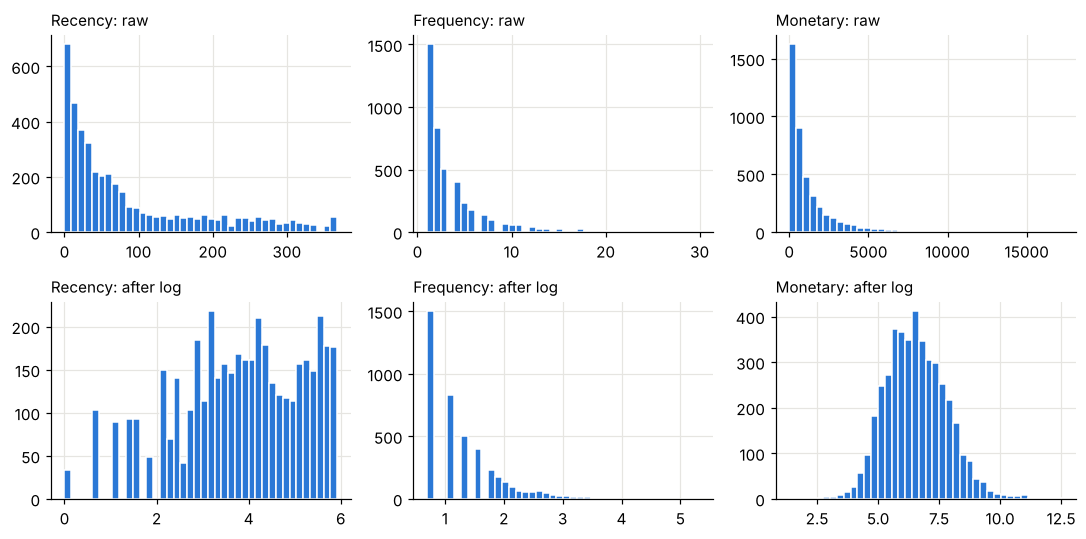

In [9]:
features = ["Recency", "Frequency", "Monetary"]
logged = np.log1p(rfm[features])
print("Skewness after log:")
print(logged.skew().round(2))

scaled = pd.DataFrame(StandardScaler().fit_transform(logged),
                      columns=["R_scaled", "F_scaled", "M_scaled"])
X = scaled.values
print()
print("Scaled means (about 0):", scaled.mean().round(3).to_dict())
print("Scaled std devs (about 1):", scaled.std(ddof=0).round(3).to_dict())

fig, axes = plt.subplots(2, 3, figsize=(10, 5))
for j, c in enumerate(features):
    r = rfm[c]
    axes[0, j].hist(r[r <= r.quantile(0.99)], bins=40, color=BLUE, edgecolor="white")
    axes[0, j].set_title(f"{c}: raw", loc="left", fontsize=10)
    axes[1, j].hist(logged[c], bins=40, color=BLUE, edgecolor="white")
    axes[1, j].set_title(f"{c}: after log", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 6. Choose the number of groups (K)
K-Means needs us to say how many groups to make. We try K = 2 to 10 and look at two measures:
- **Inertia (elbow method):** total distance from customers to their group centre. It always falls as K grows, so we look for where the drop slows down.
- **Silhouette score:** from -1 to 1; how well each customer fits its own group compared with the nearest other group. Higher is better.

K   inertia   silhouette
2     6,463   0.434
3     4,846   0.340
4     3,932   0.339
5     3,302   0.316
6     2,850   0.313
7     2,548   0.309
8     2,333   0.301
9     2,158   0.293
10    1,991   0.278


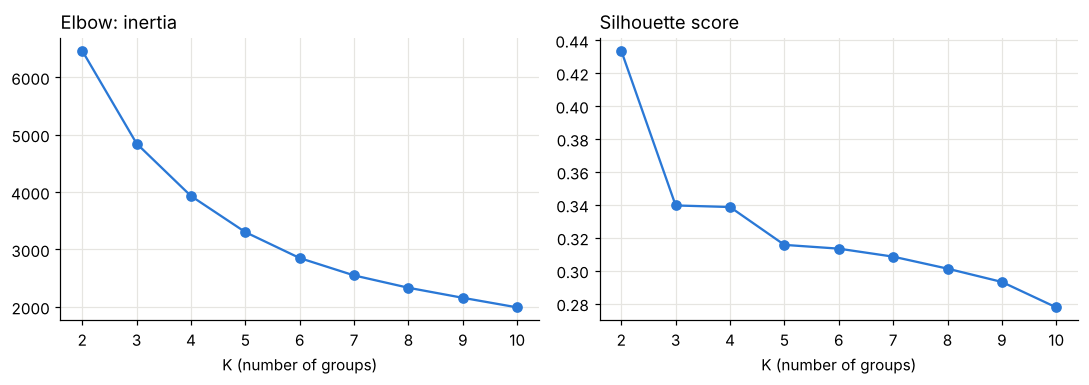

In [10]:
ks = list(range(2, 11))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

print("K   inertia   silhouette")
for k, i, s in zip(ks, inertia, sil):
    print(f"{k:<3}{i:>8,.0f}   {s:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(ks, inertia, marker="o", color=BLUE); axes[0].set_title("Elbow: inertia", loc="left")
axes[1].plot(ks, sil, marker="o", color=BLUE); axes[1].set_title("Silhouette score", loc="left")
for ax in axes:
    ax.set_xlabel("K (number of groups)"); ax.set_xticks(ks)
plt.tight_layout(); plt.show()

**Decision: K = 4.** The elbow bends gently around 3-4 (there is no sharp elbow). K = 2 has the best silhouette (0.434) but only separates "active" from "gone", which is too crude to act on. K = 3 and K = 4 score almost the same (0.340 vs 0.339), and K = 4 gives four distinct, actionable segments. So the choice combines the metrics with business usefulness.

## 7. Cluster and name the segments
K-Means only gives numbered groups (0-3). We read each group's typical (median) Recency, Frequency and Monetary values and give it a business name.

Silhouette score for K=4: 0.339
                  Customers  Recency_days  Orders   Spend  Pct_customers  Pct_revenue
Segment                                                                              
Champions               682           8.0    10.0  3696.0           16.0         64.0
Loyal Regulars         1189          53.0     4.0  1327.0           28.0         24.0
Recent Newcomers        813          16.0     2.0   471.0           19.0          5.0
Lapsed                 1638         173.0     1.0   290.0           38.0          7.0


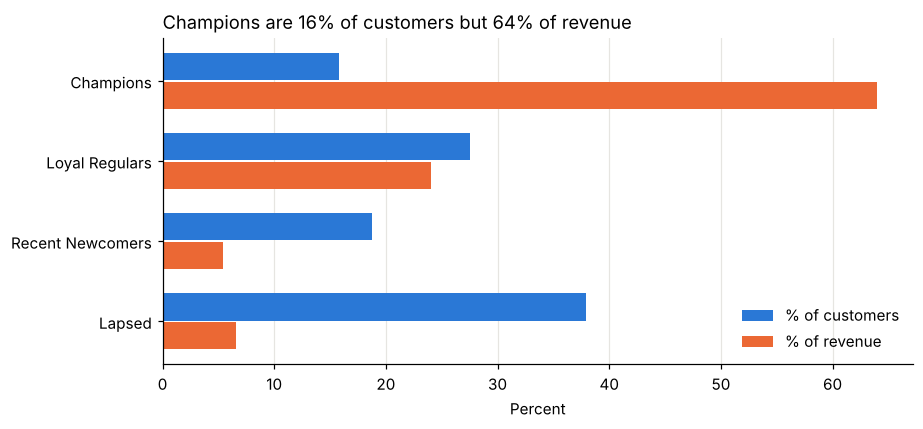

In [11]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
rfm["Cluster"] = km.labels_
print("Silhouette score for K=4:", round(silhouette_score(X, km.labels_), 3))

# name clusters from their own numbers (cluster ids are arbitrary)
g = rfm.groupby("Cluster").agg(rev=("Monetary", "sum"), rec=("Recency", "median"))
names = {g["rev"].idxmax(): "Champions"}
rest = g.drop(index=g["rev"].idxmax())
names[rest["rec"].idxmax()] = "Lapsed"
rest = rest.drop(index=rest["rec"].idxmax())
names[rest["rec"].idxmin()] = "Recent Newcomers"
names[rest["rec"].idxmax()] = "Loyal Regulars"
rfm["Segment"] = rfm["Cluster"].map(names)

order = ["Champions", "Loyal Regulars", "Recent Newcomers", "Lapsed"]
seg = rfm.groupby("Segment").agg(Customers=("CustomerID", "size"),
                                 Recency_days=("Recency", "median"),
                                 Orders=("Frequency", "median"),
                                 Spend=("Monetary", "median"),
                                 Revenue=("Monetary", "sum")).loc[order]
seg["Pct_customers"] = (100 * seg["Customers"] / seg["Customers"].sum()).round(1)
seg["Pct_revenue"] = (100 * seg["Revenue"] / seg["Revenue"].sum()).round(1)
print(seg.drop(columns="Revenue").round(0).to_string())

fig, ax = plt.subplots(figsize=(8.5, 4))
y = np.arange(len(order))[::-1]
ax.barh(y + 0.18, seg["Pct_customers"], height=0.34, color=BLUE, label="% of customers")
ax.barh(y - 0.18, seg["Pct_revenue"], height=0.34, color=ORANGE, label="% of revenue")
ax.set_yticks(y); ax.set_yticklabels(order); ax.set_xlabel("Percent")
ax.set_title("Champions are 16% of customers but 64% of revenue", loc="left")
ax.legend(frameon=False); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

rfm.to_csv("data/customer_segments.csv", index=False)

## 8. What the business should do
| Segment | Who they are | Action |
|---|---|---|
| **Champions** | Bought about a week ago, about 10 orders, highest spend, 64% of revenue | VIP treatment and early access. Don't waste discounts on people who already buy. |
| **Loyal Regulars** | Steady buyers, a few orders, decent spend | Bundles and offers that raise order size and frequency. |
| **Recent Newcomers** | Recent but only about 2 orders and low spend | Welcome offer to encourage a second and third order. |
| **Lapsed** | One order, long ago (about 6 months), low spend; 38% of customers but only 7% of revenue | Cheap win-back email; don't spend heavily. |

## Limitations and next steps
- Only one year of data, so seasonality and growth can't be separated.
- No sharp elbow and a moderate silhouette (0.34): segments overlap at the edges, which is normal for behavioural data. K was chosen partly by business judgment.
- Cancellations were matched to purchases by exact customer, product, price and quantity; partial returns are not modelled.
- Next: add features (basket size, product categories), compare with hierarchical clustering or Gaussian mixtures, and A/B test the campaigns.